# Import Library

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

# Load Dataset

In [ ]:
df = pd.read_csv('/content/flight.csv')
df.head()

,MEMBER_NO,FFP_DATE,FIRST_FLIGHT_DATE,GENDER,FFP_TIER,WORK_CITY,WORK_PROVINCE,WORK_COUNTRY,AGE,LOAD_TIME,FLIGHT_COUNT,BP_SUM,SUM_YR_1,SUM_YR_2,SEG_KM_SUM,LAST_FLIGHT_DATE,LAST_TO_END,AVG_INTERVAL,MAX_INTERVAL,EXCHANGE_COUNT,avg_discount,Points_Sum,Point_NotFlight
0,54993,11/2/2006,12/24/2008,Male,6,.,beijing,CN,31.0,3/31/2014,210,505308,239560.0,234188.0,580717,3/31/2014,1,3.483254,18,34,0.961639,619760,50
1,28065,2/19/2007,8/3/2007,Male,6,NaN,beijing,CN,42.0,3/31/2014,140,362480,171483.0,167434.0,293678,3/25/2014,7,5.194245,17,29,1.252314,415768,33
2,55106,2/1/2007,8/30/2007,Male,6,.,beijing,CN,40.0,3/31/2014,135,351159,163618.0,164982.0,283712,3/21/2014,11,5.298507,18,20,1.254676,406361,26
3,21189,8/22/2008,8/23/2008,Male,5,Los Angeles,CA,US,64.0,3/31/2014,23,337314,116350.0,125500.0,281336,12/26/2013,97,27.863636,73,11,1.090870,372204,12
4,39546,4/10/2009,4/15/2009,Male,6,guiyang,guizhou,CN,48.0,3/31/2014,152,273844,124560.0,130702.0,309928,3/27/2014,5,4.788079,47,27,0.970658,338813,39


# Data Preprocessing

## Data Cleaning

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62988 entries, 0 to 62987
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   MEMBER_NO          62988 non-null  int64  
 1   FFP_DATE           62988 non-null  object 
 2   FIRST_FLIGHT_DATE  62988 non-null  object 
 3   GENDER             62985 non-null  object 
 4   FFP_TIER           62988 non-null  int64  
 5   WORK_CITY          60719 non-null  object 
 6   WORK_PROVINCE      59740 non-null  object 
 7   WORK_COUNTRY       62962 non-null  object 
 8   AGE                62568 non-null  float64
 9   LOAD_TIME          62988 non-null  object 
 10  FLIGHT_COUNT       62988 non-null  int64  
 11  BP_SUM             62988 non-null  int64  
 12  SUM_YR_1           62437 non-null  float64
 13  SUM_YR_2           62850 non-null  float64
 14  SEG_KM_SUM         62988 non-null  int64  
 15  LAST_FLIGHT_DATE   62988 non-null  object 
 16  LAST_TO_END        629

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.duplicated('MEMBER_NO').sum()

np.int64(0)

In [ ]:
null_count = df.isnull().sum()
percent = (df.isnull().mean()*100).round(2)
df_null = pd.concat([null_count, percent], axis =1, keys=['count', 'percent'])
df_null

,count,percent
MEMBER_NO,0,0.00
FFP_DATE,0,0.00
FIRST_FLIGHT_DATE,0,0.00
GENDER,3,0.00
FFP_TIER,0,0.00
WORK_CITY,2269,3.60
WORK_PROVINCE,3248,5.16
WORK_COUNTRY,26,0.04
AGE,420,0.67
LOAD_TIME,0,0.00


In [ ]:
# total misssing value
df_nan = df[df.isna().any(axis=1)]
print(f'Presentase total missing value: {round(len(df_nan)/len(df)*100, 2)}%')

Presentase total missing value: 7.51%


In [ ]:
cat_col = ['MEMBER_NO','WORK_CITY','WORK_PROVINCE','WORK_COUNTRY']
for i in cat_col:
  jumlah = df[i].nunique()
  print(f'Jumlah nilai unik kolom {i}: {jumlah}')

Jumlah nilai unik kolom MEMBER_NO: 62988
Jumlah nilai unik kolom WORK_CITY: 3234
Jumlah nilai unik kolom WORK_PROVINCE: 1165
Jumlah nilai unik kolom WORK_COUNTRY: 118


Karena jumlah nilai unik pada kolom Work City, Work Province dan Work Country sangat banyak sehingga jika dilakukan feature encoding akan menyebabkan curse dimentionally maka perlu dilakukan drop pada kolom tersebut.

In [ ]:
df = df.drop(df[cat_col], axis=1)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62988 entries, 0 to 62987
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   FFP_DATE           62988 non-null  object 
 1   FIRST_FLIGHT_DATE  62988 non-null  object 
 2   GENDER             62985 non-null  object 
 3   FFP_TIER           62988 non-null  int64  
 4   AGE                62568 non-null  float64
 5   LOAD_TIME          62988 non-null  object 
 6   FLIGHT_COUNT       62988 non-null  int64  
 7   BP_SUM             62988 non-null  int64  
 8   SUM_YR_1           62437 non-null  float64
 9   SUM_YR_2           62850 non-null  float64
 10  SEG_KM_SUM         62988 non-null  int64  
 11  LAST_FLIGHT_DATE   62988 non-null  object 
 12  LAST_TO_END        62988 non-null  int64  
 13  AVG_INTERVAL       62988 non-null  float64
 14  MAX_INTERVAL       62988 non-null  int64  
 15  EXCHANGE_COUNT     62988 non-null  int64  
 16  avg_discount       629

In [ ]:
df = df.drop(df[['AGE','GENDER']], axis = 1)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62988 entries, 0 to 62987
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   FFP_DATE           62988 non-null  object 
 1   FIRST_FLIGHT_DATE  62988 non-null  object 
 2   FFP_TIER           62988 non-null  int64  
 3   LOAD_TIME          62988 non-null  object 
 4   FLIGHT_COUNT       62988 non-null  int64  
 5   BP_SUM             62988 non-null  int64  
 6   SUM_YR_1           62437 non-null  float64
 7   SUM_YR_2           62850 non-null  float64
 8   SEG_KM_SUM         62988 non-null  int64  
 9   LAST_FLIGHT_DATE   62988 non-null  object 
 10  LAST_TO_END        62988 non-null  int64  
 11  AVG_INTERVAL       62988 non-null  float64
 12  MAX_INTERVAL       62988 non-null  int64  
 13  EXCHANGE_COUNT     62988 non-null  int64  
 14  avg_discount       62988 non-null  float64
 15  Points_Sum         62988 non-null  int64  
 16  Point_NotFlight    629

Melakukan drop kolom AGE dan Gender karena tidak relevan karena AGE dan GENDER itu atribut demografis statis yang tidak mencerminkan perilaku/value customer terhadap maskapai.

## Change Data Type

In [ ]:
date_col = ['FFP_DATE', 'LOAD_TIME', 'FIRST_FLIGHT_DATE','LAST_FLIGHT_DATE']

for col in date_col:
  df[col] = pd.to_datetime(df[col], errors='coerce')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62988 entries, 0 to 62987
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   FFP_DATE           62988 non-null  datetime64[ns]
 1   FIRST_FLIGHT_DATE  62988 non-null  datetime64[ns]
 2   FFP_TIER           62988 non-null  int64         
 3   LOAD_TIME          62988 non-null  datetime64[ns]
 4   FLIGHT_COUNT       62988 non-null  int64         
 5   BP_SUM             62988 non-null  int64         
 6   SUM_YR_1           62437 non-null  float64       
 7   SUM_YR_2           62850 non-null  float64       
 8   SEG_KM_SUM         62988 non-null  int64         
 9   LAST_FLIGHT_DATE   62567 non-null  datetime64[ns]
 10  LAST_TO_END        62988 non-null  int64         
 11  AVG_INTERVAL       62988 non-null  float64       
 12  MAX_INTERVAL       62988 non-null  int64         
 13  EXCHANGE_COUNT     62988 non-null  int64         
 14  avg_di

In [ ]:
df.isnull().sum()

,0
FFP_DATE,0
FIRST_FLIGHT_DATE,0
FFP_TIER,0
LOAD_TIME,0
FLIGHT_COUNT,0
BP_SUM,0
SUM_YR_1,551
SUM_YR_2,138
SEG_KM_SUM,0
LAST_FLIGHT_DATE,421


Setelah mengubah data type pada kolom terdapat missing value pada LAST_FLIGHT_DATE sebanyak 421 baris

In [ ]:
df.describe()

,FFP_DATE,FIRST_FLIGHT_DATE,FFP_TIER,LOAD_TIME,FLIGHT_COUNT,BP_SUM,SUM_YR_1,SUM_YR_2,SEG_KM_SUM,LAST_FLIGHT_DATE,LAST_TO_END,AVG_INTERVAL,MAX_INTERVAL,EXCHANGE_COUNT,avg_discount,Points_Sum,Point_NotFlight
count,62988,62988,62988.000000,62988,62988.000000,62988.000000,62437.000000,62850.000000,62988.000000,62567,62988.000000,62988.000000,62988.000000,62988.000000,62988.000000,62988.0000,62988.000000
mean,2010-03-06 23:58:48.672128,2010-09-01 17:59:44.911411968,4.102162,2014-03-30 23:59:59.999999744,11.839414,10925.081254,5355.376064,5604.026014,17123.878691,2013-10-06 15:32:03.103233280,176.120102,67.749788,166.033895,0.319775,0.721558,12545.7771,2.728155
min,2004-11-01 00:00:00,1905-12-31 00:00:00,4.000000,2014-03-31 00:00:00,2.000000,0.000000,0.000000,0.000000,368.000000,2012-04-01 00:00:00,1.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000
25%,2008-04-12 00:00:00,2008-12-14 18:00:00,4.000000,2014-03-31 00:00:00,3.000000,2518.000000,1003.000000,780.000000,4747.000000,2013-07-07 00:00:00,29.000000,23.370370,79.000000,0.000000,0.611997,2775.0000,0.000000
50%,2010-10-08 00:00:00,2011-04-23 00:00:00,4.000000,2014-03-31 00:00:00,7.000000,5700.000000,2800.000000,2773.000000,9994.000000,2013-12-14 00:00:00,108.000000,44.666667,143.000000,0.000000,0.711856,6328.5000,0.000000
75%,2012-03-29 00:00:00,2012-07-26 00:00:00,4.000000,2014-03-31 00:00:00,15.000000,12831.000000,6574.000000,6845.750000,21271.250000,2014-03-03 00:00:00,268.000000,82.000000,228.000000,0.000000,0.809476,14302.5000,1.000000
max,2013-03-31 00:00:00,2015-05-30 00:00:00,6.000000,2014-03-31 00:00:00,213.000000,505308.000000,239560.000000,234188.000000,580717.000000,2014-03-31 00:00:00,731.000000,728.000000,728.000000,46.000000,1.500000,985572.0000,140.000000
std,NaN,NaN,0.373856,NaN,14.049471,16339.486151,8109.450147,8703.364247,20960.844623,NaN,183.822223,77.517866,123.397180,1.136004,0.185427,20507.8167,7.364164


Terdapat kejanggalan pada kolom nilai min SUM_YR_1, SUM_YR_2, SEG_KM_SUM, avg_discount, karena jika nilai SUM_YR_1, SUM_YR_2, dan avg_discount sama dengan 0 maka seharusnya nilai min SEG_KM_SUM adalah 0 karena customer tersebut belum melakukan perjalanan disaat data diambil. Akan tetapi, nilai min SEG_KM_SUM > 0 maka terdapat ketidaksesuain data. Hal ini sejalan dengan kriteria yang dikemukakan oleh Tao (2020).  

In [ ]:
# Drop data yang tidak sesuai
df.drop(df[(df['SUM_YR_1'] == 0) & (df['SUM_YR_2'] == 0) & (df['avg_discount'] == 0) & (df['SEG_KM_SUM'] > 0)].index, inplace = True)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 62981 entries, 0 to 62987
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   FFP_DATE           62981 non-null  datetime64[ns]
 1   FIRST_FLIGHT_DATE  62981 non-null  datetime64[ns]
 2   FFP_TIER           62981 non-null  int64         
 3   LOAD_TIME          62981 non-null  datetime64[ns]
 4   FLIGHT_COUNT       62981 non-null  int64         
 5   BP_SUM             62981 non-null  int64         
 6   SUM_YR_1           62430 non-null  float64       
 7   SUM_YR_2           62843 non-null  float64       
 8   SEG_KM_SUM         62981 non-null  int64         
 9   LAST_FLIGHT_DATE   62560 non-null  datetime64[ns]
 10  LAST_TO_END        62981 non-null  int64         
 11  AVG_INTERVAL       62981 non-null  float64       
 12  MAX_INTERVAL       62981 non-null  int64         
 13  EXCHANGE_COUNT     62981 non-null  int64         
 14  avg_discoun

In [ ]:
null_count = df.isnull().sum()
percent = (df.isnull().mean()*100).round(2)
df_null = pd.concat([null_count, percent], axis =1, keys=['count', 'percent'])
df_null

,count,percent
FFP_DATE,0,0.00
FIRST_FLIGHT_DATE,0,0.00
FFP_TIER,0,0.00
LOAD_TIME,0,0.00
FLIGHT_COUNT,0,0.00
BP_SUM,0,0.00
SUM_YR_1,551,0.87
SUM_YR_2,138,0.22
SEG_KM_SUM,0,0.00
LAST_FLIGHT_DATE,421,0.67


In [ ]:
# total misssing value
df_nan = df[df.isna().any(axis=1)]
print(f'Presentase total missing value: {round(len(df_nan)/len(df)*100, 2)}%')

Presentase total missing value: 1.76%


In [ ]:
# Drop missing value yang tersisa
df = df.dropna()
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 61871 entries, 0 to 62978
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   FFP_DATE           61871 non-null  datetime64[ns]
 1   FIRST_FLIGHT_DATE  61871 non-null  datetime64[ns]
 2   FFP_TIER           61871 non-null  int64         
 3   LOAD_TIME          61871 non-null  datetime64[ns]
 4   FLIGHT_COUNT       61871 non-null  int64         
 5   BP_SUM             61871 non-null  int64         
 6   SUM_YR_1           61871 non-null  float64       
 7   SUM_YR_2           61871 non-null  float64       
 8   SEG_KM_SUM         61871 non-null  int64         
 9   LAST_FLIGHT_DATE   61871 non-null  datetime64[ns]
 10  LAST_TO_END        61871 non-null  int64         
 11  AVG_INTERVAL       61871 non-null  float64       
 12  MAX_INTERVAL       61871 non-null  int64         
 13  EXCHANGE_COUNT     61871 non-null  int64         
 14  avg_discoun

# Feature Selection

Menggunakan LRFMC model. Penjelasan LRFMC menurut Tao (2020) adalah sebagai berikut:

- L (LOYALTY) : Lama waktu user menjadi membership (dalam bulan) dalam diketahui dari selisih dari waktu observasi dengan waktu menjadi menjadi membership.
- R (RECENCY) : Jumlah bulan sejak penerbangan terakhir anggota dari akhir waktu observasi.
- F (FREQUENCY) : Total berapa kali user telah terbang selama periode observasi.
- M (MONETERY) : Miles atau jarak yang terakumulasi selama waktu observasi user.
- C (DISCOUNT) : Nilai rata-rata discount factor yang digunakan user selama periode observasi.

Maka feature yang diambil :

- FPP_DATE (Frequent Flyer Program Join Date)
- LOAD_TIME (Tanggal Data Diambil)
- FLIGHT_COUNT (Jumlah Penerbangan Customer)
- avg_discount (Rata-rata Discount yang Diadapat Customer)
- SEG_KM_SUM (Total Jarak (km) Penerbangan yang Sudah Dilakukan)
- LAST_TO_END (Jarak Waktu Penerbangan Terakhir ke Pesanan Penerbangan Paling Terakhir)

In [ ]:
df_features = df[['FFP_DATE', 'LOAD_TIME', 'FLIGHT_COUNT', 'avg_discount', 'SEG_KM_SUM', 'LAST_TO_END']]

In [ ]:
# membuat feature untuk loyalti dari feature yang sudah ada
df_features['TIME_MONTH'] = ((df_features['LOAD_TIME'] - df_features['FFP_DATE']).dt.days/30).astype(int)
df_selection = df_features[['TIME_MONTH', 'FLIGHT_COUNT', 'SEG_KM_SUM', 'LAST_TO_END', 'avg_discount']]
df_selection.info()

<class 'pandas.core.frame.DataFrame'>
Index: 61871 entries, 0 to 62978
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   TIME_MONTH    61871 non-null  int64  
 1   FLIGHT_COUNT  61871 non-null  int64  
 2   SEG_KM_SUM    61871 non-null  int64  
 3   LAST_TO_END   61871 non-null  int64  
 4   avg_discount  61871 non-null  float64
dtypes: float64(1), int64(4)
memory usage: 2.8 MB


## EDA

In [ ]:
df_selection.describe()

,TIME_MONTH,FLIGHT_COUNT,SEG_KM_SUM,LAST_TO_END,avg_discount
count,61871.000000,61871.000000,61871.000000,61871.000000,61871.000000
mean,49.078324,11.917587,17249.477801,173.732944,0.721942
std,28.254923,14.094971,21039.298821,181.513988,0.184938
min,12.000000,2.000000,368.000000,1.000000,0.112043
25%,24.000000,3.000000,4840.500000,29.000000,0.612660
50%,42.000000,7.000000,10132.000000,107.000000,0.711974
75%,72.000000,15.000000,21389.000000,262.000000,0.809284
max,114.000000,213.000000,580717.000000,731.000000,1.500000


<Axes: >

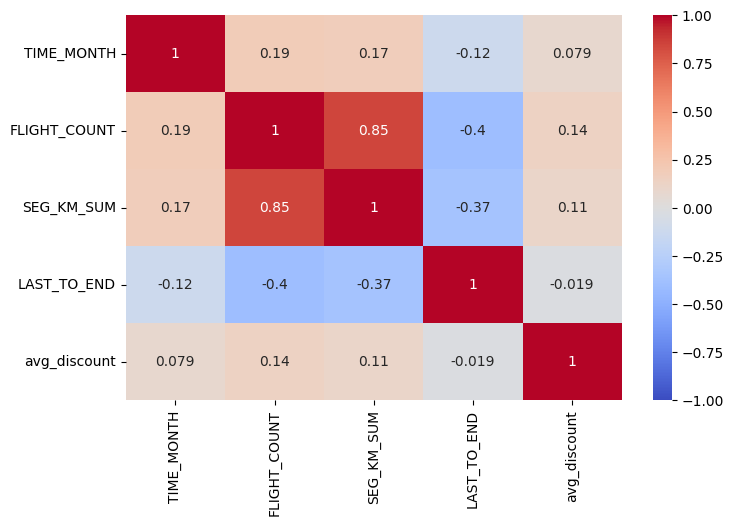

In [ ]:
plt.figure(figsize=(8,5))
sns.heatmap(df_selection.corr(),annot=True,cmap='coolwarm',vmin=-1.,vmax=1.)

- FLIGHT_COUNT dan SEG_KM_SUM berkorelasi sangat kuat (0,85). Semakin sering terbang, semakin besar total jaraknya. Keduanya membawa informasi yang mirip.
- LAST_TO_END berkorelasi negatif sedang dengan aktivitas (-0,40 dengan frekuensi, -0,37 dengan jarak). Pelanggan yang sering terbang cenderung baru saja terbang.
- TIME_MONTH dan avg_discount hampir tidak berkorelasi dengan fitur lain (di bawah 0,2), jadi menyumbang informasi yang berbeda.

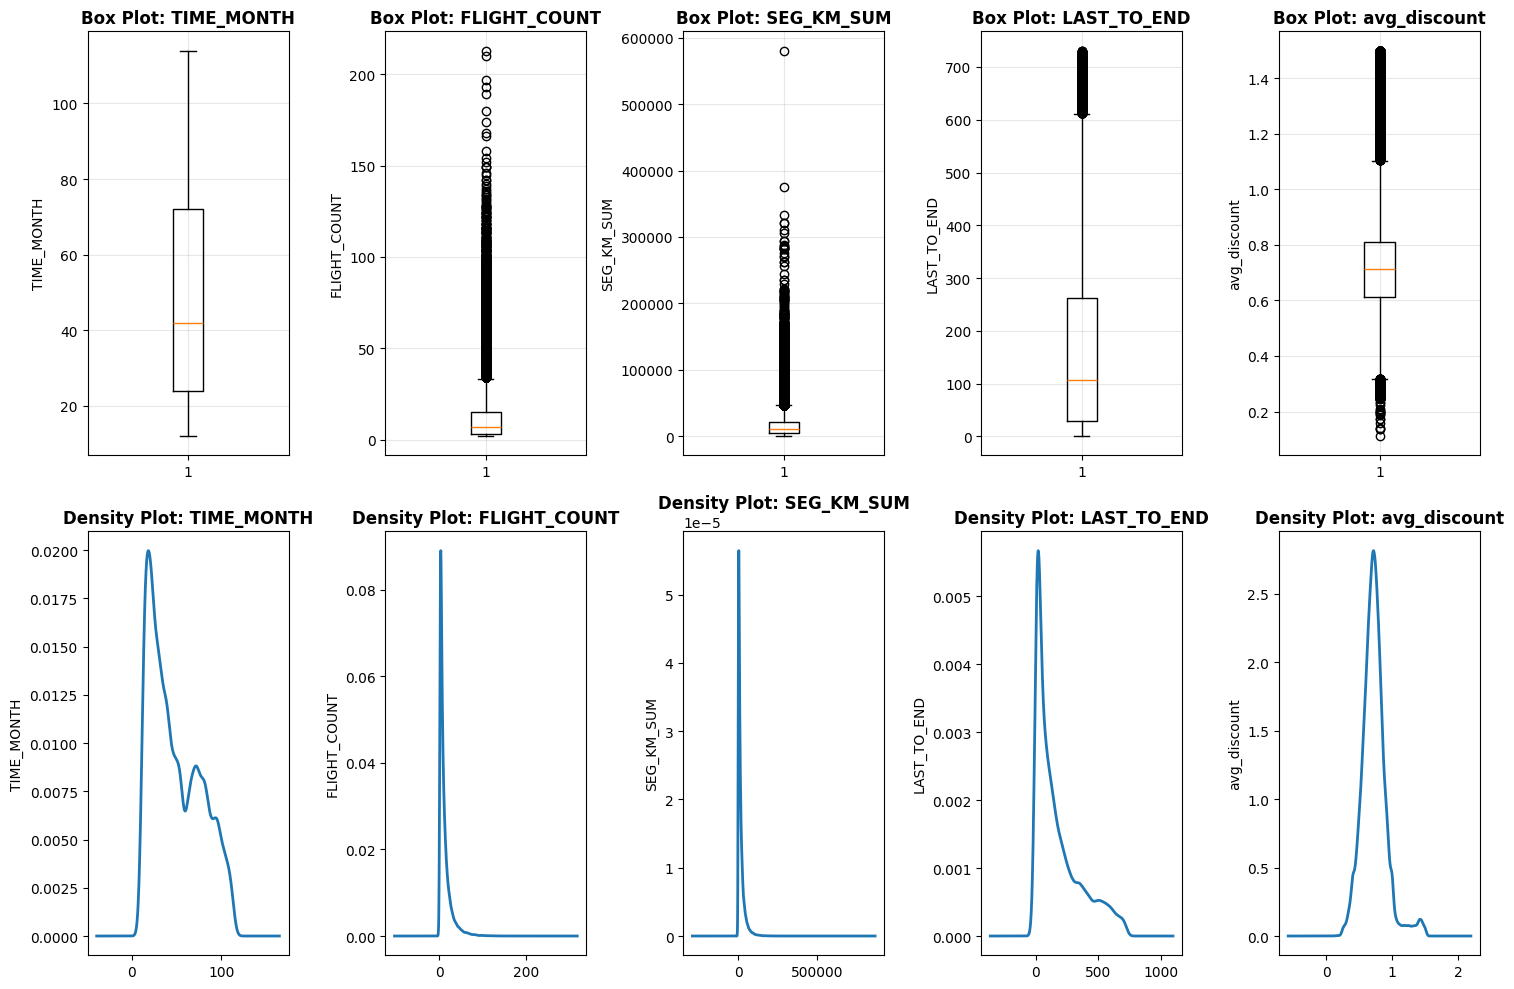

In [ ]:
fig, axes = plt.subplots(2,5, figsize=(15,10))

for i, col in enumerate(df_selection.columns.to_list()):
  axes[0,i].boxplot(df_selection[col], vert=True)
  axes[0,i].set_title(f'Box Plot: {col}', fontsize=12, fontweight='bold')
  axes[0,i].set_ylabel(f'{col}')
  axes[0,i].grid(True, alpha=0.3)

for i, col in enumerate(df_selection.columns.to_list()):
  df_selection[col].plot(kind ='density', ax=axes[1,i],  linewidth=2)
  axes[1,i].set_title(f'Density Plot: {col}', fontsize=12, fontweight='bold')
  axes[1,i].set_ylabel(f'{col}')

plt.tight_layout()
plt.show()

melakukan transformasi log karena beberapa kolom tidak terdistribusi normal yang dapat mempengaruhi clustering

In [ ]:
col_log = ['FLIGHT_COUNT', 'SEG_KM_SUM','LAST_TO_END']

for col in col_log:
  df_selection[col] = np.log1p(df_selection[col])

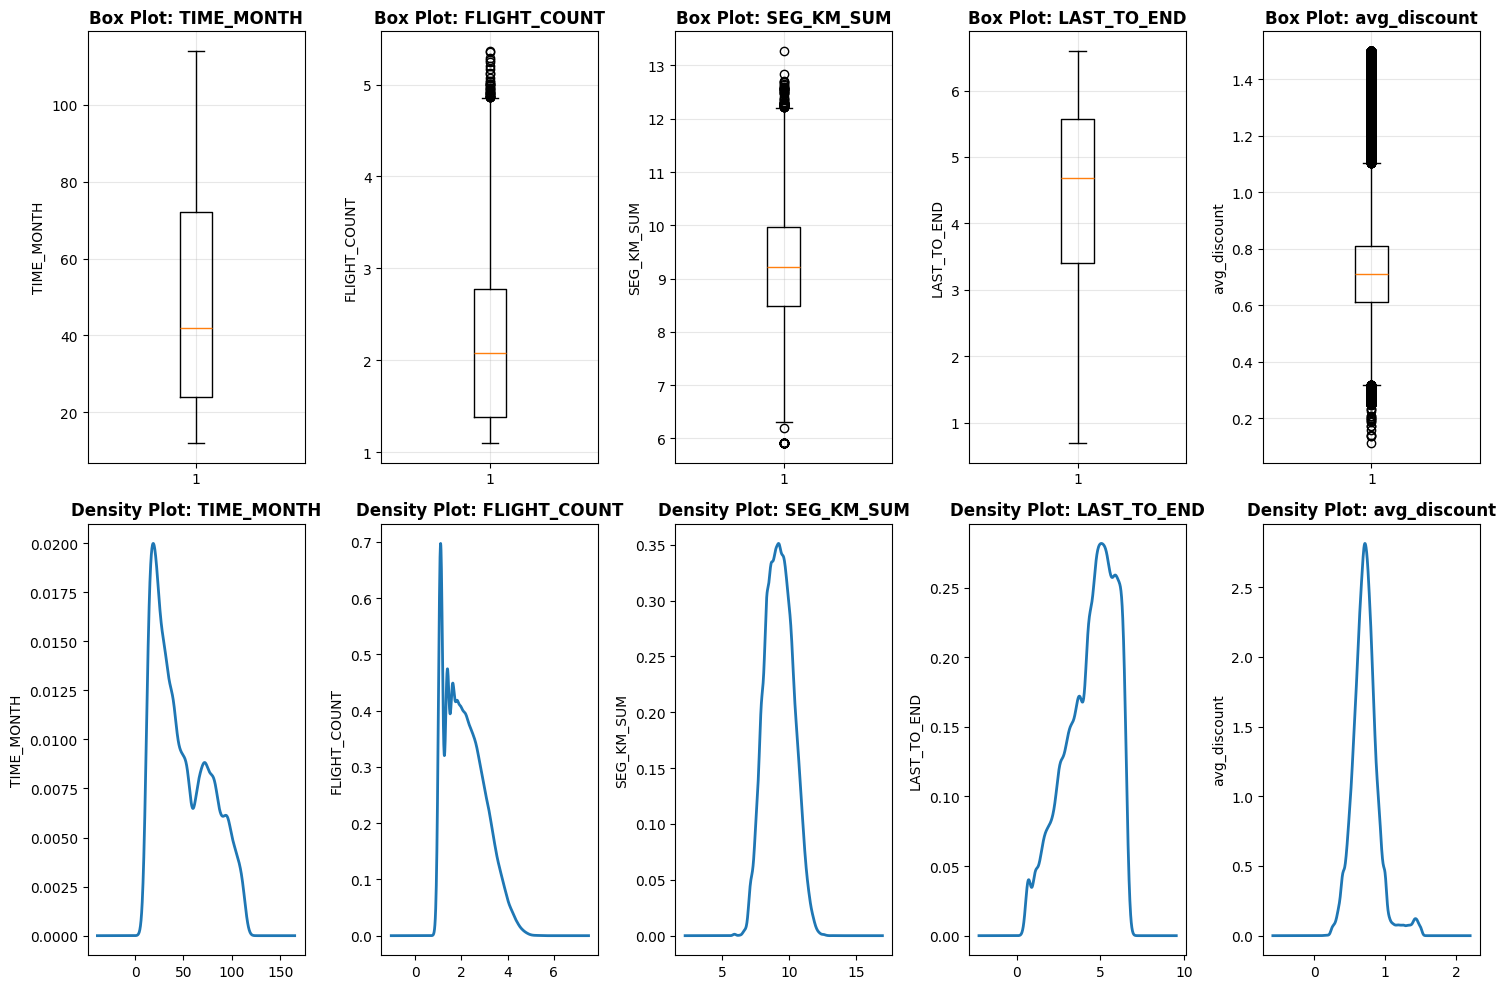

In [ ]:
fig, axes = plt.subplots(2,5, figsize=(15,10))

for i, col in enumerate(df_selection.columns.to_list()):
  axes[0,i].boxplot(df_selection[col], vert=True)
  axes[0,i].set_title(f'Box Plot: {col}', fontsize=12, fontweight='bold')
  axes[0,i].set_ylabel(f'{col}')
  axes[0,i].grid(True, alpha=0.3)

for i, col in enumerate(df_selection.columns.to_list()):
  df_selection[col].plot(kind ='density', ax=axes[1,i],  linewidth=2)
  axes[1,i].set_title(f'Density Plot: {col}', fontsize=12, fontweight='bold')
  axes[1,i].set_ylabel(f'{col}')

plt.tight_layout()
plt.show()

karena kolom LAST_TO_END masih kurang terdistribusi normal maka menggunakan metode transformasi akar kuadrat

In [ ]:
df_selection['LAST_TO_END'] = np.expm1(df_selection['LAST_TO_END'])
df_selection['LAST_TO_END'] = np.sqrt(df_selection['LAST_TO_END'])

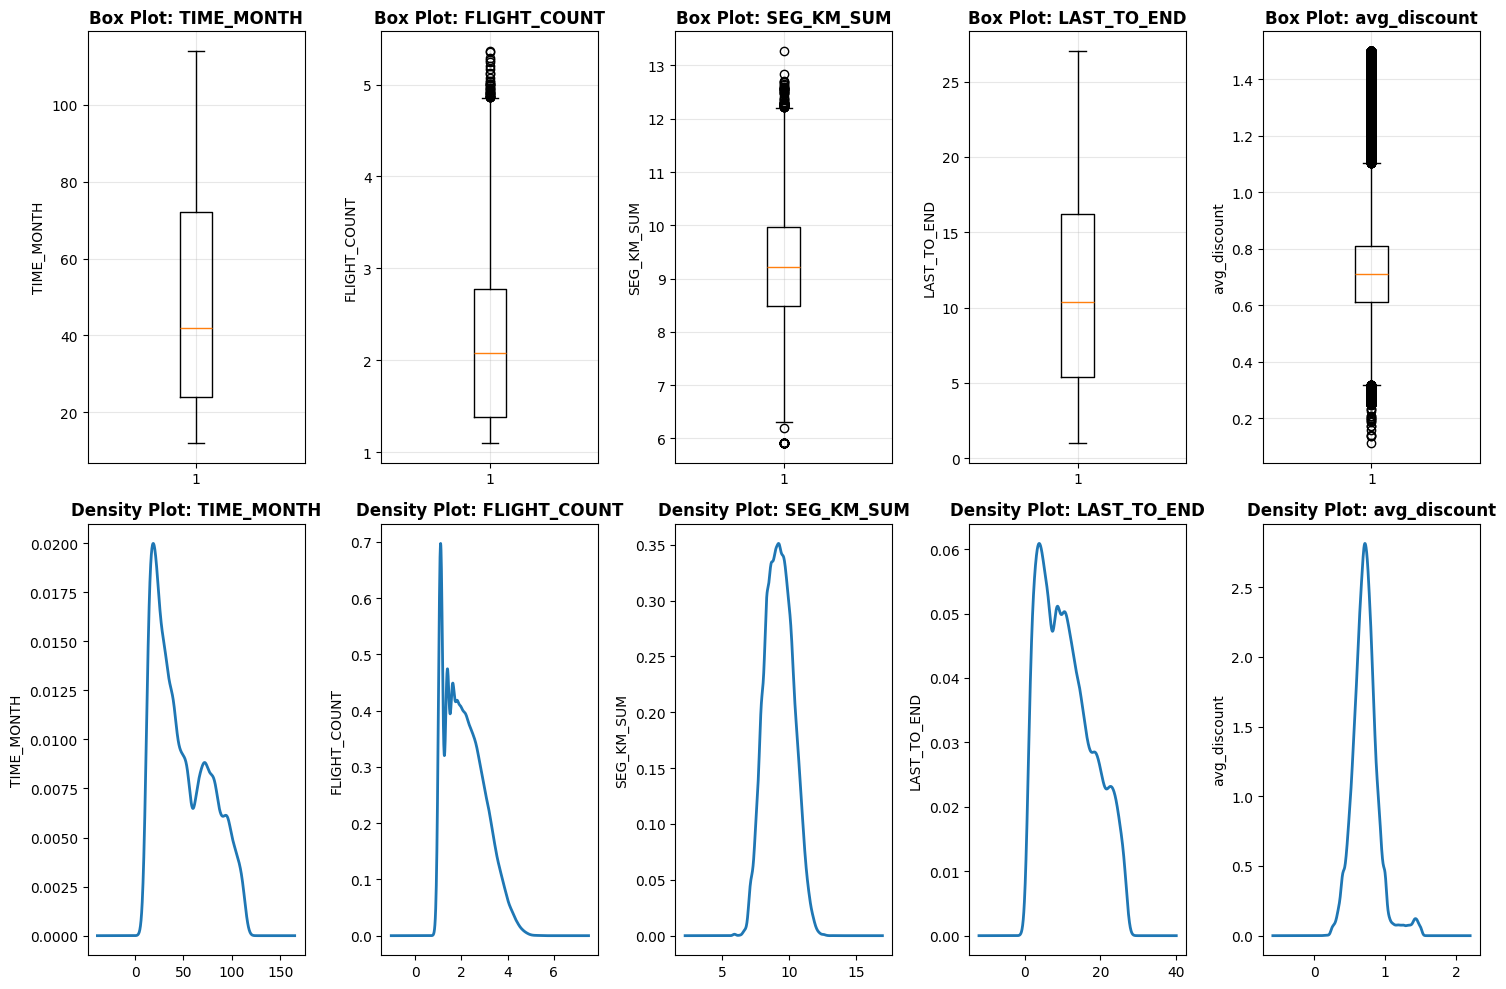

In [ ]:
fig, axes = plt.subplots(2,5, figsize=(15,10))

for i, col in enumerate(df_selection.columns.to_list()):
  axes[0,i].boxplot(df_selection[col], vert=True)
  axes[0,i].set_title(f'Box Plot: {col}', fontsize=12, fontweight='bold')
  axes[0,i].set_ylabel(f'{col}')
  axes[0,i].grid(True, alpha=0.3)

for i, col in enumerate(df_selection.columns.to_list()):
  df_selection[col].plot(kind ='density', ax=axes[1,i],  linewidth=2)
  axes[1,i].set_title(f'Density Plot: {col}', fontsize=12, fontweight='bold')
  axes[1,i].set_ylabel(f'{col}')

plt.tight_layout()
plt.show()

## Scalling

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_selection)
df_scaled = pd.DataFrame(df_scaled, columns = df_selection.columns.to_list())
df_scaled.head()

,TIME_MONTH,FLIGHT_COUNT,SEG_KM_SUM,LAST_TO_END,avg_discount
0,1.448314,3.819566,3.969667,-1.493740,1.296099
1,1.306745,3.335099,3.298039,-1.253966,2.867853
2,1.342137,3.291706,3.264029,-1.156224,2.880619
3,0.669683,1.206961,3.255744,-0.204522,1.994880
4,0.386544,3.433265,3.351093,-1.313654,1.344866


# Clustering

## Using Elbow Method

In [ ]:
# inertia
from sklearn.cluster import KMeans
inertia = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=0)
    kmeans.fit(df_scaled.values)
    inertia.append(kmeans.inertia_)
    nilai_inertia = kmeans.inertia_
    print ('Jumlah kluster: ', i, 'Nilai Inertia: ', nilai_inertia)

Jumlah kluster:  1 Nilai Inertia:  309355.0000000036
Jumlah kluster:  2 Nilai Inertia:  206290.17235919312
Jumlah kluster:  3 Nilai Inertia:  179705.7109104093
Jumlah kluster:  4 Nilai Inertia:  154924.55877129282
Jumlah kluster:  5 Nilai Inertia:  137822.55899827485
Jumlah kluster:  6 Nilai Inertia:  128261.97067381913
Jumlah kluster:  7 Nilai Inertia:  118017.7246795781
Jumlah kluster:  8 Nilai Inertia:  108902.0439635321
Jumlah kluster:  9 Nilai Inertia:  100176.46007921181
Jumlah kluster:  10 Nilai Inertia:  95540.1837610182


<Axes: >

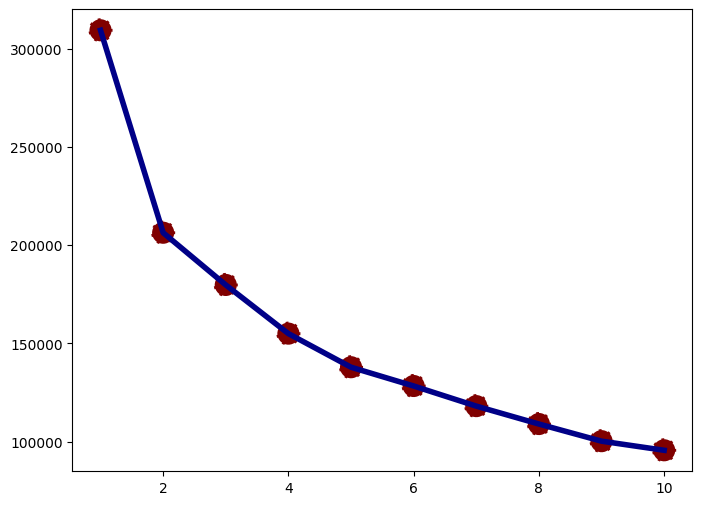

In [ ]:
plt.figure(figsize=(8, 6))

sns.lineplot(x=range(1, 11), y=inertia, color='#000087', linewidth = 4)
sns.scatterplot(x=range(1, 11), y=inertia, s=300, color='#800000',  linestyle='--')

k optimal yang didapat berdasarkan metode elbow adalah
2, 4 dan 5

## Using Silhouette Method

In [ ]:
from sklearn.metrics import silhouette_score

list_silhoutte_score = []
for i in range(2,11):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(df_scaled)
    pred = kmeans.predict(df_scaled)

    score_euclidean = silhouette_score(df_scaled, pred, metric='euclidean')
    list_silhoutte_score.append(score_euclidean)

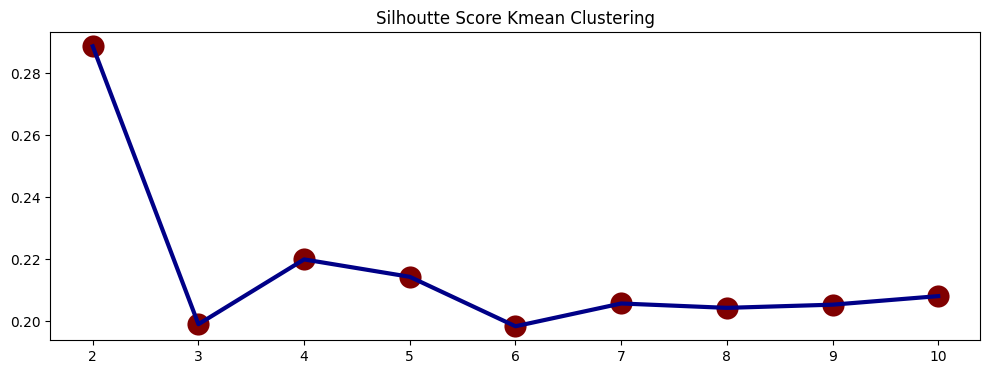

In [ ]:
fig, ax = plt.subplots(figsize=(12,4))
sns.lineplot(x=range(2, 11), y=list_silhoutte_score, color="#000087", linewidth = 3)
sns.scatterplot(x=range(2, 11), y=list_silhoutte_score, s=300, color='#800000')
plt.title("Silhoutte Score Kmean Clustering")

plt.show()

Untuk metode silhoutte score nilai k yang optimal adah 2,4,5

### K = 2

In [ ]:
from sklearn.cluster import KMeans
kmeans_2 = KMeans(n_clusters=2, random_state=42)
kmeans_2.fit(df_scaled.values)

KMeans(n_clusters=2, random_state=42)

In [ ]:
df_scaled['cluster'] = kmeans_2.labels_

df_scaled.head()

,TIME_MONTH,FLIGHT_COUNT,SEG_KM_SUM,LAST_TO_END,avg_discount,cluster
0,1.448314,3.819566,3.969667,-1.493740,1.296099,0
1,1.306745,3.335099,3.298039,-1.253966,2.867853,0
2,1.342137,3.291706,3.264029,-1.156224,2.880619,0
3,0.669683,1.206961,3.255744,-0.204522,1.994880,0
4,0.386544,3.433265,3.351093,-1.313654,1.344866,0


In [ ]:
df_scaled.groupby(['cluster']).agg( {
                                'TIME_MONTH' : ['mean','median'],
                                'FLIGHT_COUNT' : ['mean','median'],
                                'SEG_KM_SUM' : ['mean', 'median'],
                                'LAST_TO_END' : ['mean','median'],
                                'avg_discount' : ['mean', 'median']
                              } )

TIME_MONTH           FLIGHT_COUNT           SEG_KM_SUM            \
              mean    median         mean    median       mean    median   
cluster                                                                    
0         0.239684  0.103405     0.860763  0.792512   0.829396  0.770547   
1        -0.203967 -0.498265    -0.732496 -0.678293  -0.705803 -0.676115   

        LAST_TO_END           avg_discount            
               mean    median         mean    median  
cluster                                               
0         -0.674213 -0.802490     0.129155  0.007979  
1          0.573745  0.560485    -0.109909 -0.118649

Poin utama:

- Pembeda utama: frekuensi terbang, total jarak, dan recency
Lama keanggotaan dan diskon tidak banyak membedakan kedua cluster
- Terlalu umum untuk strategi bisnis, sehingga dibandingkan dengan k = 4 dan k = 5

In [ ]:
from sklearn.decomposition import PCA

fitur = ['TIME_MONTH', 'FLIGHT_COUNT', 'SEG_KM_SUM', 'LAST_TO_END', 'avg_discount']
pca = PCA(n_components=2)

pcs = pca.fit_transform(df_scaled[fitur])

data_pca = pd.DataFrame(data = pcs, columns = ['PC 1', 'PC 2'])
data_pca['clusters_2'] = df_scaled['cluster']
data_pca.head()

,PC 1,PC 2,clusters_2
0,5.806090,0.842424,0
1,5.149157,2.230437,0
2,5.064091,2.283817,0
3,3.103625,1.508423,0
4,4.912218,0.475124,0


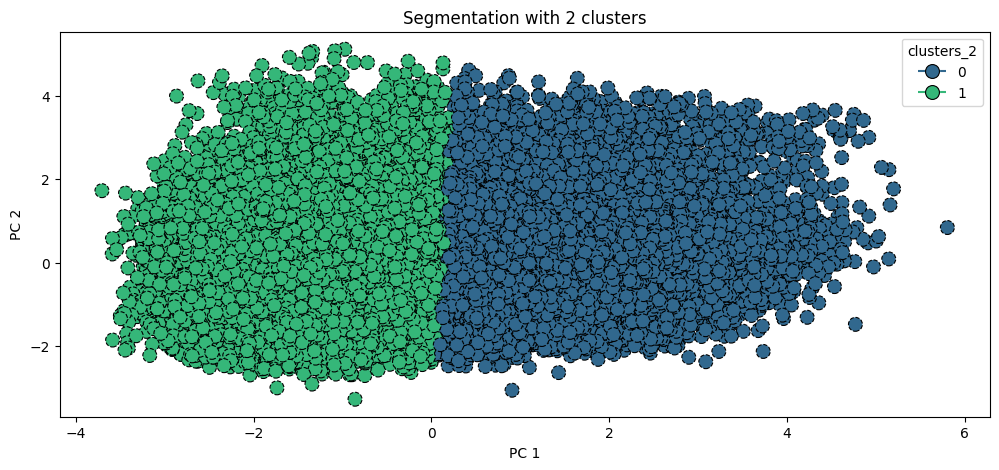

In [ ]:
fig, ax = plt.subplots(figsize=(12,5))

sns.scatterplot( x="PC 1", y="PC 2", hue="clusters_2",data=data_pca, edgecolor='black', linestyle='--', s = 100,
                palette='viridis', ax=ax)
plt.title("Segmentation with 2 clusters")
plt.show()

Data 5 fitur diproyeksikan ke 2 dimensi (PC 1 dan PC 2) dengan PCA
- Pemisahan hanya terjadi pada sumbu PC 1: cluster 0 di kanan (aktif), cluster 1 di kiri (kurang aktif)
- Sepanjang PC 2, kedua cluster menyebar sama, jadi PC 2 tidak ikut membedakan segmen
- Kedua cluster saling bersentuhan di tengah tanpa celah, artinya pelanggan berubah bertahap dari kurang aktif ke aktif, bukan dua kelompok yang terpisah tegas
- Pembelahan ini sejalan dengan profil cluster: PC 1 didominasi frekuensi terbang, jarak, dan recency

### K = 4

In [ ]:
kmeans_4 = KMeans(n_clusters=4, random_state=42)
kmeans_4.fit(df_scaled.values)

KMeans(n_clusters=4, random_state=42)

In [ ]:
df_scaled = df_scaled.drop("cluster", axis = 1)
df_scaled['cluster'] = kmeans_4.labels_

df_scaled.head()

,TIME_MONTH,FLIGHT_COUNT,SEG_KM_SUM,LAST_TO_END,avg_discount,cluster
0,1.448314,3.819566,3.969667,-1.493740,1.296099,2
1,1.306745,3.335099,3.298039,-1.253966,2.867853,2
2,1.342137,3.291706,3.264029,-1.156224,2.880619,2
3,0.669683,1.206961,3.255744,-0.204522,1.994880,2
4,0.386544,3.433265,3.351093,-1.313654,1.344866,2


In [ ]:
df_scaled.groupby(['cluster']).agg( {
                                'TIME_MONTH' : ['mean','median'],
                                'FLIGHT_COUNT' : ['mean','median'],
                                'SEG_KM_SUM' : ['mean', 'median'],
                                'LAST_TO_END' : ['mean','median'],
                                'avg_discount' : ['mean', 'median']
                              } )

TIME_MONTH           FLIGHT_COUNT           SEG_KM_SUM            \
              mean    median         mean    median       mean    median   
cluster                                                                    
0        -0.582040 -0.639834     0.811468  0.719650   0.788171  0.727349   
1        -0.385697 -0.639834    -0.683218 -0.678293  -0.589518 -0.562742   
2         1.247346  1.200568     0.909373  0.861208   0.866861  0.818166   
3         0.050603 -0.144341    -0.807259 -0.946480  -0.872161 -0.872851   

        LAST_TO_END           avg_discount            
               mean    median         mean    median  
cluster                                               
0         -0.676241 -0.789904     0.053800 -0.017706  
1          0.327331  0.287906    -0.732345 -0.661243  
2         -0.663436 -0.789904     0.183055  0.039643  
3          0.922930  1.035138     0.790301  0.634643

Poin utama:

- Pembeda utama: frekuensi, jarak, recency, dan lama keanggotaan
- Terdapat beberapa cluster sehingga dapat mendetail untuk masing" cluster

In [ ]:
pca = PCA(n_components=2)

pcs = pca.fit_transform(df_scaled[fitur])

data_pca = pd.DataFrame(data = pcs, columns = ['PC 1', 'PC 2'])
data_pca['clusters_4'] = df_scaled['cluster']
data_pca.head()

,PC 1,PC 2,clusters_4
0,5.806090,0.842424,2
1,5.149157,2.230437,2
2,5.064091,2.283817,2
3,3.103625,1.508423,2
4,4.912218,0.475124,2


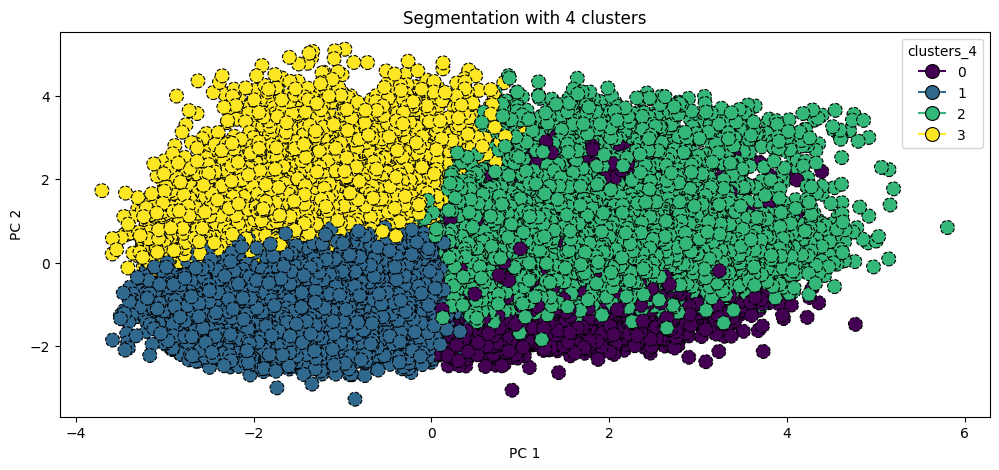

In [ ]:
fig, ax = plt.subplots(figsize=(12,5))

sns.scatterplot( x="PC 1", y="PC 2", hue="clusters_4",data=data_pca, edgecolor='black', linestyle='--', s = 100,
                palette='viridis', ax=ax)
plt.title("Segmentation with 4 clusters")
plt.show()

Data 5 fitur diproyeksikan ke 2 dimensi (PC 1 dan PC 2) dengan PCA:
- PC 1 (kiri ke kanan) memisahkan tingkat aktivitas: cluster 1 dan 3 di kiri (aktivitas rendah), cluster 0 dan 2 di kanan (aktivitas tinggi)
- PC 2 (bawah ke atas) membagi tiap sisi menjadi dua segmen:
  - Kiri: cluster 3 (atas, berisiko churn, diskon tinggi) dan cluster 1 (bawah, pasif)
  - Kanan: cluster 2 (atas, loyal bernilai tinggi) dan cluster 0 (bawah, aktif berkembang)
- Pemisahan lebih terlihat dibanding k = 2, dan tiap segmen menempati area yang cukup jelas
- Ada tumpang tindih di area tengah, artinya perubahan antar segmen terjadi bertahap

### k = 5

In [ ]:
kmeans_5 = KMeans(n_clusters=5, random_state=42)
kmeans_5.fit(df_scaled.values)

KMeans(n_clusters=5, random_state=42)

In [ ]:
df_scaled = df_scaled.drop("cluster", axis = 1)
df_scaled['cluster'] = kmeans_5.labels_

df_scaled.head()

,TIME_MONTH,FLIGHT_COUNT,SEG_KM_SUM,LAST_TO_END,avg_discount,cluster
0,1.448314,3.819566,3.969667,-1.493740,1.296099,2
1,1.306745,3.335099,3.298039,-1.253966,2.867853,2
2,1.342137,3.291706,3.264029,-1.156224,2.880619,2
3,0.669683,1.206961,3.255744,-0.204522,1.994880,2
4,0.386544,3.433265,3.351093,-1.313654,1.344866,2


In [ ]:
df_scaled.groupby(['cluster']).agg( {
                                'TIME_MONTH' : ['mean','median'],
                                'FLIGHT_COUNT' : ['mean','median'],
                                'SEG_KM_SUM' : ['mean', 'median'],
                                'LAST_TO_END' : ['mean','median'],
                                'avg_discount' : ['mean', 'median']
                              } )

TIME_MONTH           FLIGHT_COUNT           SEG_KM_SUM            \
              mean    median         mean    median       mean    median   
cluster                                                                    
0        -0.582022 -0.639834     0.811314  0.719650   0.788044  0.727327   
1        -0.080998 -0.285911    -0.822833 -0.946480  -0.899556 -0.897216   
2         1.239331  1.200568     1.381566  1.303161   1.260474  1.207201   
3         1.255243  1.200568    -0.161650 -0.113415  -0.073560 -0.015908   
4        -0.617720 -0.781404    -0.694918 -0.678293  -0.604362 -0.587717   

        LAST_TO_END           avg_discount            
               mean    median         mean    median  
cluster                                               
0         -0.676182 -0.789904     0.053728 -0.017701  
1          0.987422  1.097893     0.843150  0.690140  
2         -0.848550 -0.987874     0.392054  0.160113  
3         -0.204881 -0.219392    -0.271464 -0.276429  
4          0.386005  0.358211    -0.731616 -0.659373

Poin utama:

- Lima segmen dengan profil berbeda, sehingga tiap segmen punya strategi sendiri
- Cluster 1 menjadi target utama kampanye win-back berbasis diskon
- Cluster 3 adalah peluang: anggota lama yang masih bisa dibujuk sebelum menjadi seperti cluster 1
- Dibanding k = 4, anggota lama dengan aktivitas sedang (cluster 3) kini muncul sebagai segmen tersendiri

In [ ]:
pca = PCA(n_components=2)

pcs = pca.fit_transform(df_scaled[fitur])

data_pca = pd.DataFrame(data = pcs, columns = ['PC 1', 'PC 2'])
data_pca['clusters_5'] = df_scaled['cluster']
data_pca.head()

,PC 1,PC 2,clusters_5
0,5.806090,0.842424,2
1,5.149157,2.230437,2
2,5.064091,2.283817,2
3,3.103625,1.508423,2
4,4.912218,0.475124,2


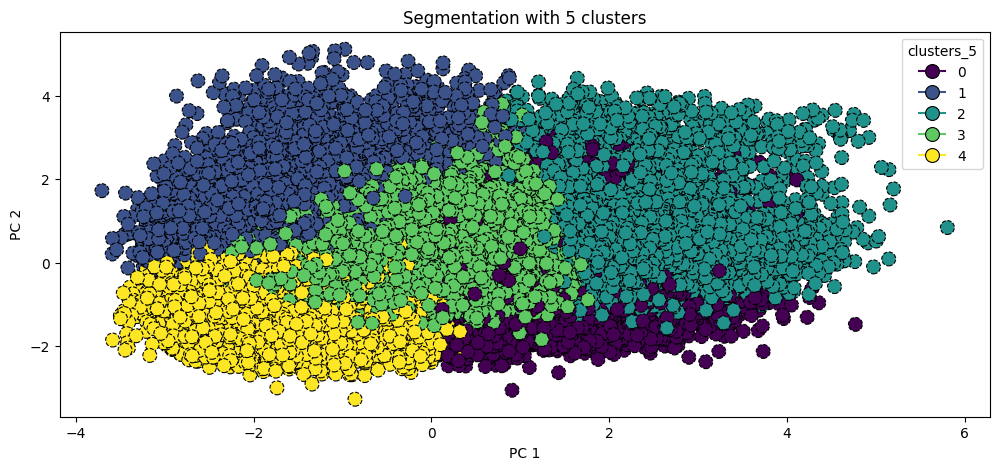

In [ ]:
fig, ax = plt.subplots(figsize=(12,5))

sns.scatterplot( x="PC 1", y="PC 2", hue="clusters_5",data=data_pca, edgecolor='black', linestyle='--', s = 100,
                palette='viridis', ax=ax)
plt.title("Segmentation with 5 clusters")
plt.show()

Visualisasi Segmentasi (k = 5, PCA)

- PC 1 (kiri ke kanan) memisahkan tingkat aktivitas: cluster 1 dan 4 di kiri (aktivitas rendah), cluster 0 dan 2 di kanan (aktivitas tinggi)
- PC 2 (bawah ke atas) membagi tiap sisi:
  - Kiri: cluster 1 (atas, berisiko churn, diskon tinggi) dan cluster 4 (bawah, anggota baru pasif)
  - Kanan: cluster 2 (atas, loyal bernilai tinggi) dan cluster 0 (bawah, aktif berkembang)
- Cluster 3 (hijau) berada di tengah sebagai segmen transisi: anggota lama dengan aktivitas sedang. Ini yang membedakan k = 5 dari k = 4
- Tumpang tindih terbesar ada di sekitar cluster 3, artinya perubahan antar segmen terjadi bertahap

Memilih k = 5 sebagai nilai paling optimal

# Hasil Akhir

In [ ]:
print(fitur)

['TIME_MONTH', 'FLIGHT_COUNT', 'SEG_KM_SUM', 'LAST_TO_END', 'avg_discount']


In [ ]:
df_features2 = df[['FFP_DATE', 'LOAD_TIME', 'FLIGHT_COUNT', 'avg_discount', 'SEG_KM_SUM', 'LAST_TO_END']]

In [ ]:
df_features2['TIME_MONTH'] = ((df_features2['LOAD_TIME'] - df_features2['FFP_DATE']).dt.days/30).astype(int)
df_selection2 = df_features2[['TIME_MONTH', 'FLIGHT_COUNT', 'SEG_KM_SUM', 'LAST_TO_END', 'avg_discount']]
df_selection2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 61871 entries, 0 to 62978
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   TIME_MONTH    61871 non-null  int64  
 1   FLIGHT_COUNT  61871 non-null  int64  
 2   SEG_KM_SUM    61871 non-null  int64  
 3   LAST_TO_END   61871 non-null  int64  
 4   avg_discount  61871 non-null  float64
dtypes: float64(1), int64(4)
memory usage: 2.8 MB


In [ ]:
df_selection2.head()

,TIME_MONTH,FLIGHT_COUNT,SEG_KM_SUM,LAST_TO_END,avg_discount
0,90,210,580717,1,0.961639
1,86,140,293678,7,1.252314
2,87,135,283712,11,1.254676
3,68,23,281336,97,1.090870
4,60,152,309928,5,0.970658


In [ ]:
df_selection_cluster = df_selection2.copy()
df_selection_cluster['cluster'] = kmeans_5.labels_
df_selection_cluster.groupby(['cluster']).agg( {
                                'TIME_MONTH' : ['mean','median'],
                                'FLIGHT_COUNT' : ['mean','median'],
                                'SEG_KM_SUM' : ['mean', 'median'],
                                'LAST_TO_END' : ['mean','median'],
                                'avg_discount' : ['mean', 'median']
                              } )

TIME_MONTH        FLIGHT_COUNT           SEG_KM_SUM           \
              mean median         mean median          mean   median   
cluster                                                                
0        32.633458   31.0    19.371986   15.0  28178.146085  21604.0   
1        46.789762   41.0     3.835541    3.0   5237.561104   4152.0   
2        84.095238   83.0    31.232319   25.0  44034.687460  35164.0   
3        84.544819   83.0     7.521320    7.0  11347.532439  10159.0   
4        31.624821   27.0     4.370119    4.0   6736.322679   5685.0   

        LAST_TO_END        avg_discount            
               mean median         mean    median  
cluster                                            
0         59.871511   34.0     0.731879  0.718669  
1        357.572627  353.0     0.877872  0.849575  
2         41.699910   20.0     0.794448  0.751553  
3        121.766277   95.0     0.671739  0.670821  
4        229.428214  188.0     0.586640  0.600000

Poin utama:

- Cluster 2 (Pelanggan Setia Utama) anggota sekitar 7 tahun, terbang paling sering dan paling jauh. Pertahankan dengan program loyalitas.
- Cluster 0 (Pelanggan Aktif Berkembang) anggota baru (sekitar 2,7 tahun) dengan aktivitas tinggi. Dorong agar naik menjadi seperti cluster 2.
- Cluster 3 (Anggota lama Mulai Menjauh) sama-sama anggota lama seperti cluster 2, tetapi frekuensinya jauh lebih rendah. Bujuk kembali sebelum makin pasif.
- Cluster 1 (Pemburu Diskon) hampir setahun tidak terbang dengan frekuensi terendah, tetapi diskonnya tertinggi. Target utama kampanye win-back berbasis diskon.
- Cluster 4 (Anggota Baru Pasif) anggota baru yang belum aktif. Butuh aktivasi, misalnya promo penerbangan pertama atau kedua.

Rekomendasi Bisnis:

- Pertahankan yang bernilai: Loyalist paling berharga (31 penerbangan, 44 rb km), jadi kehilangan mereka paling mahal.
- Cegah sebelum terlambat: Drifting Veterans adalah peluang paling murah. Mereka masih cukup baru terbang (sekitar 4 bulan) dan lebih mudah dibujuk daripada At-Risk Deal Seekers.
- Diskon jangan disebar rata: Segmen 1 responsif terhadap diskon, sedangkan Loyalist dan Rising Flyers sudah aktif. Diskon di sana berisiko membuang margin.

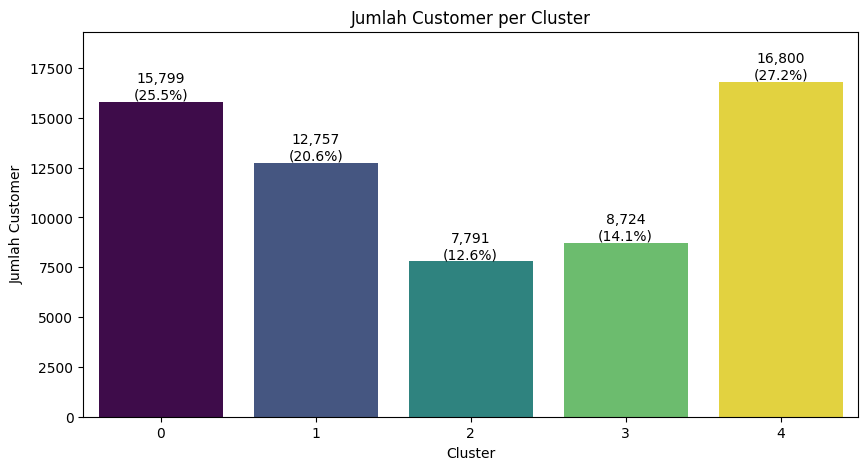

In [ ]:
order = sorted(df_selection_cluster["cluster"].unique())
total = len(df_selection_cluster)

plt.figure(figsize=(10, 5))
ax = sns.countplot(
    data=df_selection_cluster,
    x="cluster",
    hue="cluster",
    order=order,
    palette="viridis",
    legend=False,
)

# dengan hue, tiap cluster jadi container terpisah, jadi semuanya perlu dilabeli
for c in ax.containers:
    labels = [
        f"{int(b.get_height()):,}\n({b.get_height() / total:.1%})" if b.get_height() > 0 else ""
        for b in c
    ]
    ax.bar_label(c, labels=labels)

ax.margins(y=0.15)  # ruang di atas batang untuk label
plt.title("Jumlah Customer per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Jumlah Customer")
plt.show()

Poin Utama:
- Semua segmen di atas 12%, dan tidak ada yang terlalu kecil. Ini mendukung pemilihan k = 5.
- Anggota Baru Pasif (4) adalah segmen terbesar (27,2%). Aktivasi anggota baru berpotensi paling besar dampaknya.
- Pelanggan Setia Utama paling kecil (2) (12,6%), tetapi paling bernilai per pelanggan (rata-rata 31 penerbangan). Melindungi mereka tetap prioritas.
- Pelanggan Aktif Berkembang (0) dan Pemburu Diskon (1) masing-masing sekitar seperempat dan seperlima pelanggan. Keduanya segmen besar yang perlu strategi terarah.
- Sekitar 48% pelanggan (cluster 4 dan 1) berada di segmen pasif atau berisiko, jadi ruang untuk reaktivasi besar.

Rekomendasi Bisnis:
- Pelanggan Setia Utama (2): Pertahankan dengan reward eksklusif: akses lounge, prioritas boarding, upgrade gratis. Hindari diskon besar karena mereka sudah aktif.
- Pelanggan Aktif Berkembang (0): Dorong naik ke level Loyalist lewat poin bonus, tantangan jumlah penerbangan, dan percepatan naik tier.
- Anggota Baru Pasif (4): Aktivasi dengan promo penerbangan pertama atau kedua, dan onboarding yang jelas.
- Anggota Lama Mulai Menjauh (3): Kirim pengingat personal dan penawaran rute yang pernah mereka terbangi sebelum makin pasif.
- Pemburu Diskon (1): Kampanye win-back dengan diskon terbatas waktu dan anggaran dibatasi.

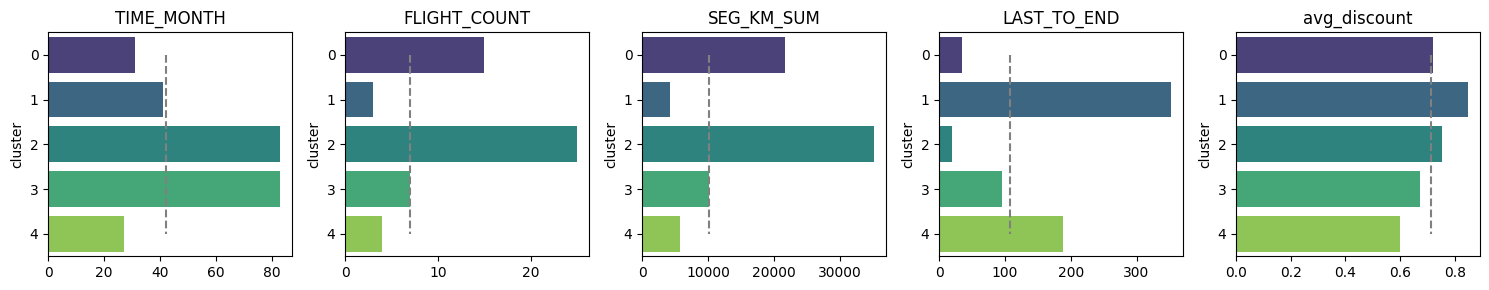

In [ ]:
plt.figure(figsize=(15,3))
for i in range(len(fitur)):
    plt.subplot(1, len(fitur), i+1)
    plt.vlines(df_selection_cluster[fitur[i]].median(), ymin=0, ymax=4, color='grey', linestyle='--')
    group = df_selection_cluster.groupby('cluster')
    index = group[fitur[i]].median().index
    value = group[fitur[i]].median().values
    sns.barplot(y = index, x = value, orient='h', palette='viridis')
    plt.title(fitur[i])

plt.tight_layout()
plt.show()

Poin utama:

- Pelanggan Setia Utama (2) unggul di semua ukuran aktivitas: member ±83 bulan, median 25 penerbangan, terakhir terbang ±20 hari lalu.
- Pelanggan Aktif Berkembang (0) member lebih baru (±31 bulan) tetapi aktivitasnya di atas median (15 penerbangan, ±34 hari).
- Anggota lama mulai menjauh (3) seperti pelanggan setia, tetapi aktivitasnya hanya setara median keseluruhan.
- Member baru pasif (4) dengan aktivitas di bawah median dan diskon terendah (0,60).
- Pemburu diskon (1) hampir setahun tidak terbang dan frekuensinya terendah (3 penerbangan), tetapi diskonnya tertinggi (0,85).
- Perbedaan diskon antar segmen kecil (0,60 sampai 0,85), jadi bukan pembeda utama. Aktivitas dan recency yang lebih membedakan segmen.

# Referensi:
1. https://books.google.co.id/books?id=CcH4DwAAQBAJ&pg=PA95&lpg=PA95&dq=chinese+member+airline+data+customer+bp_sum&source=bl&ots=MuNwvzNnN-&sig=ACfU3U0hPyubVpBG7RGuxmQgm9Zn7m2g6g&hl=en&sa=X&ved=2ahUKEwjZsKzHy7LsAhWZaCsKHW9XDW8Q6AEwCHoECAoQAg#v=onepage&q=chinese%20member%20airline%20data%20customer%20bp_sum&f=false
2. https://drive.google.com/drive/folders/1R2zzE8cTf-JwNzP-orxaGDWoQGh2qmAy
3. https://ieeexplore.ieee.org/document/9736735
4. https://ieeexplore.ieee.org/document/9967896

# Reflection Question

1. Mengapa penting melakukan preprocessing dan EDA sebelum menerapkan algoritma clustering seperti K-Means? Jelaskan bagaimana langkah-langkah awal ini berpengaruh terhadap kualitas hasil clustering dan interpretasi cluster.

    jawab

    Kualitas clustering ditentukan sebelum algoritma dijalankan. Preprocessing memastikan K-Means bekerja pada data yang adil (skala seragam, tidak dikuasai outlier), dan EDA memastikan kita memahami data sehingga cluster yang terbentuk bisa dijelaskan dan dipakai untuk keputusan bisnis. Tanpa keduanya, K-Means tetap menghasilkan cluster, tetapi tidak ada jaminan cluster itu bermakna.



2. Bagaimana penggunaan metode clustering, seperti K-Means, dapat membantu pengambilan keputusan dalam konteks bisnis nyata? Berikan contoh bagaimana segmentasi pelanggan dapat digunakan untuk strategi pemasaran atau layanan yang lebih tepat sasaran.

    jawab

    K-Means mengubah data perilaku pelanggan menjadi segmen yang bisa dinamai, diukur, dan ditindaklanjuti. Nilai bisnisnya ada pada strategi yang berbeda untuk tiap segmen: retensi untuk yang bernilai, pengembangan untuk yang berpotensi, aktivasi untuk yang pasif, dan win-back untuk yang berisiko pergi.